In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("Advertising.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (200, 5)


,Unnamed: 0,TV,radio,newspaper,sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [3]:
df = df.drop(columns=["Unnamed: 0"])

print("Updated Shape:", df.shape)
display(df.head())

Updated Shape: (200, 4)


,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [4]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   radio      200 non-null    float64
 2   newspaper  200 non-null    float64
 3   sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [5]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Missing Values:
TV           0
radio        0
newspaper    0
sales        0
dtype: int64

Duplicate Rows: 0


In [6]:
df.describe()

,TV,radio,newspaper,sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


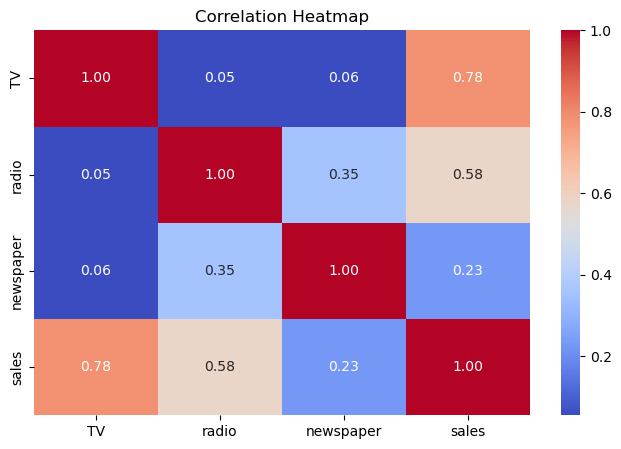

In [7]:
correlation = df.corr()

plt.figure(figsize=(8, 5))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

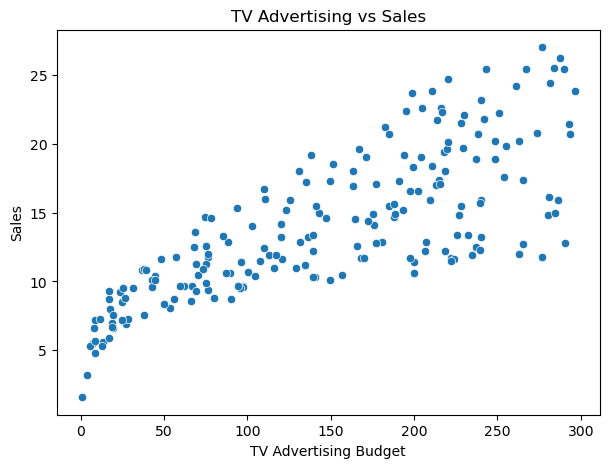

In [8]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x="TV", y="sales", data=df)

plt.title("TV Advertising vs Sales")
plt.xlabel("TV Advertising Budget")
plt.ylabel("Sales")
plt.show()

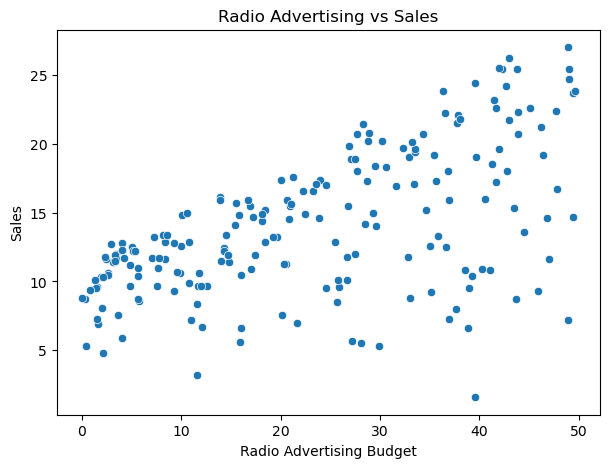

In [9]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x="radio", y="sales", data=df)

plt.title("Radio Advertising vs Sales")
plt.xlabel("Radio Advertising Budget")
plt.ylabel("Sales")
plt.show()

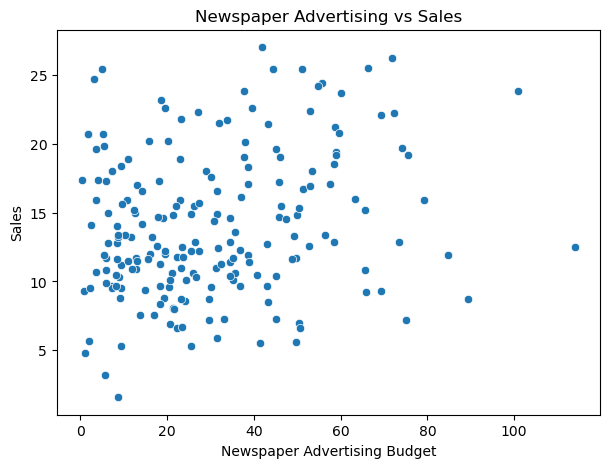

In [10]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x="newspaper", y="sales", data=df)

plt.title("Newspaper Advertising vs Sales")
plt.xlabel("Newspaper Advertising Budget")
plt.ylabel("Sales")
plt.show()

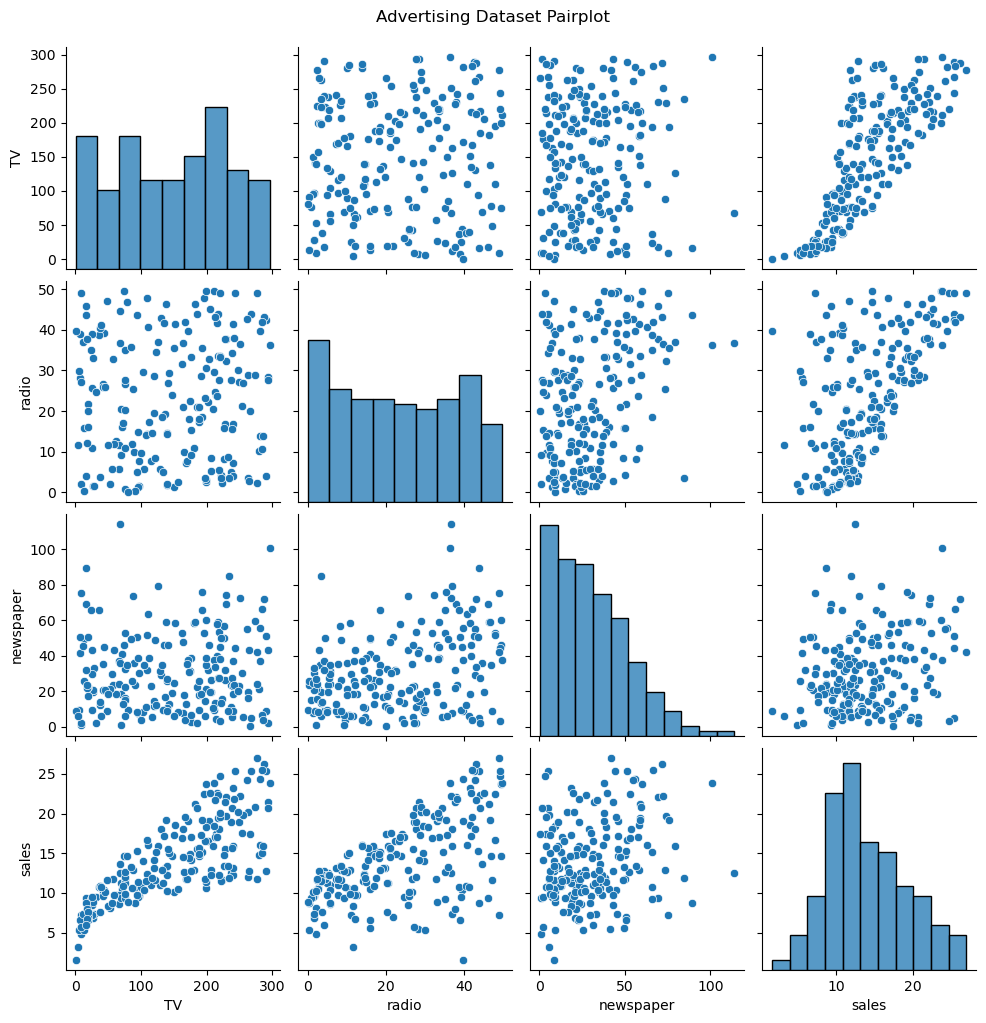

In [11]:
sns.pairplot(df)
plt.suptitle("Advertising Dataset Pairplot", y=1.02)
plt.show()

In [12]:
X = df[["TV", "radio", "newspaper"]]
y = df["sales"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (200, 3)
Target Shape: (200,)


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (160, 3)
Testing Data: (40, 3)


In [14]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [15]:
y_pred_lr = lr_model.predict(X_test)

print("Actual Sales:", list(y_test[:10]))
print("Predicted Sales:", y_pred_lr[:10])

Actual Sales: [16.9, 22.4, 21.4, 7.3, 24.7, 12.6, 22.3, 8.4, 11.5, 14.9]
Predicted Sales: [16.4080242  20.88988209 21.55384318 10.60850256 22.11237326 13.10559172
 21.05719192  7.46101034 13.60634581 15.15506967]


In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred_lr)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2 = r2_score(y_test, y_pred_lr)

print("Linear Regression Results")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

Linear Regression Results
MAE: 1.4607567168117606
RMSE: 1.7815996615334502
R2 Score: 0.899438024100912


In [17]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [18]:
y_pred_rf = rf_model.predict(X_test)

print("Actual Sales:", list(y_test[:10]))
print("Predicted Sales:", y_pred_rf[:10])

Actual Sales: [16.9, 22.4, 21.4, 7.3, 24.7, 12.6, 22.3, 8.4, 11.5, 14.9]
Predicted Sales: [17.698 21.804 20.628  6.793 22.927 13.379 22.376  9.688 11.826 15.54 ]


In [19]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Results")
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

Random Forest Results
MAE: 0.6200999999999988
RMSE: 0.7685910811348248
R2 Score: 0.9812843792541843


In [20]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, mae_rf],
    "RMSE": [rmse, rmse_rf],
    "R2 Score": [r2, r2_rf]
})

display(results)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.460757,1.781600,0.899438
1,Random Forest,0.620100,0.768591,0.981284


,Feature,Importance
0,TV,0.624810
1,radio,0.362201
2,newspaper,0.012989


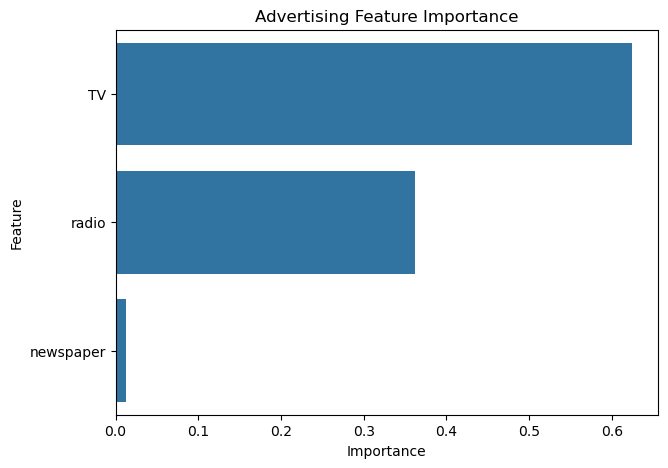

In [21]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance", ascending=False
)

display(importance)

plt.figure(figsize=(7, 5))
sns.barplot(data=importance, x="Importance", y="Feature")
plt.title("Advertising Feature Importance")
plt.show()

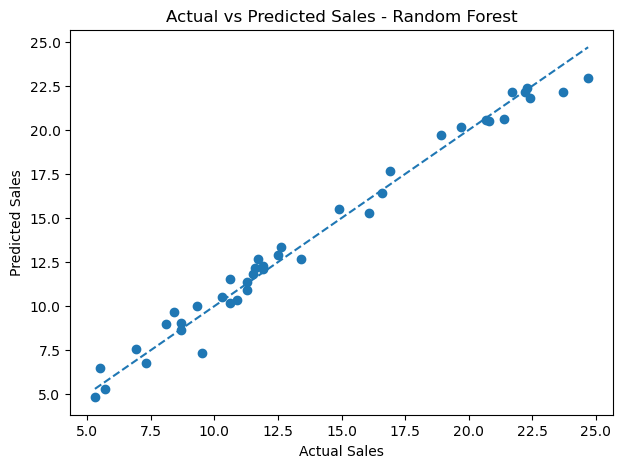

In [22]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred_rf)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales - Random Forest")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()

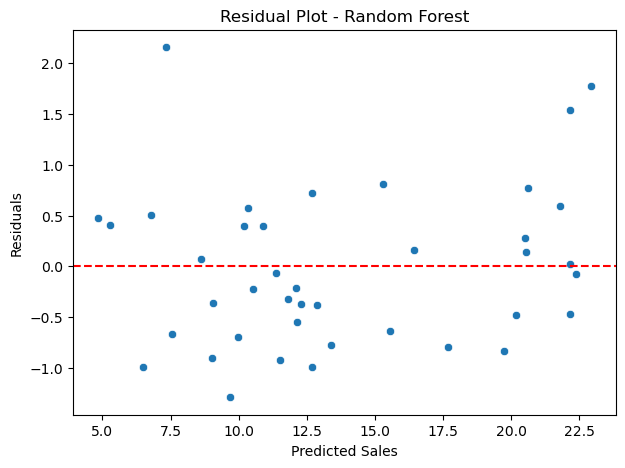

In [23]:
residuals = y_test - y_pred_rf

plt.figure(figsize=(7, 5))
sns.scatterplot(x=y_pred_rf, y=residuals)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")
plt.title("Residual Plot - Random Forest")

plt.show()

## Conclusion

In this project, we developed a Sales Prediction model using Machine Learning.

- Performed Exploratory Data Analysis (EDA).
- Analyzed TV, Radio, and Newspaper advertising budgets.
- Built two models: Linear Regression and Random Forest Regressor.
- Compared both models using MAE, RMSE, and R² Score.
- Random Forest achieved the best performance with an R² score of **98.13%**.
- TV advertising was the most important feature with **62.48% feature importance**.

**Final Result:** Random Forest Regressor performed better than Linear Regression and provided more accurate sales predictions on the test dataset.